# A/B Testing & Regression Analysis

## Facebook Ads vs Google AdWords
### Project Overview
This project analyzes the performance of two digital advertising platforms — Facebook Ads and Google AdWords — using statistical techniques such as A/B testing and regression analysis.

The objective is to determine which platform delivers better conversions and cost efficiency, and to provide data-driven recommendations for marketing budget allocation. 

## Business Problem Statement
As a digital marketing agency, our goal is to maximize return on investment (ROI) for client advertising campaigns.

We ran two separate ad campaigns on:

- Facebook Ads
- Google AdWords
Both campaigns were active throughout 2019.
We now want to evaluate their performance and determine which platform should be prioritized for future campaigns.

## Research Question
Which advertising platform performs better in terms of:

- Conversions
- Engagement (clicks)
- Cost efficiency

And is the observed difference statistically significant?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ttest_ind
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import coint
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("marketing_campaign_2019.csv")
df.tail()


,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost,Facebook_CTR,Facebook_Conversion_Rate,Facebook_CPC,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost,AdWords_CTR,AdWords_Conversion_Rate,AdWords_CPC
360,27-12-2019,5946,78,1,3488.605299,0.013118,0.012821,44.725709,9486,346,15,16337.987530,0.036475,0.043353,47.219617
361,28-12-2019,3545,57,1,2032.301045,0.016079,0.017544,35.654404,4143,139,4,7382.303717,0.033551,0.028777,53.110099
362,29-12-2019,4193,42,1,1397.882347,0.010017,0.023810,33.282913,8980,373,15,14779.629420,0.041537,0.040214,39.623671
363,30-12-2019,8681,128,3,5242.086987,0.014745,0.023438,40.953805,7140,273,11,11877.350560,0.038235,0.040293,43.506779
364,31-12-2019,8873,128,4,3472.929083,0.014426,0.031250,27.132258,11266,372,19,26127.698510,0.033020,0.051075,70.235749


# Dataset Overview
The dataset contains daily performance data for Facebook Ads and Google AdWords campaigns conducted during the year 2019.

Each row represents one day, and the dataset includes metrics such as:

- Ad views (impressions)
- Clicks
- Conversions
- Cost
- Derived metrics like CTR, CPC, and conversion rate

In [3]:
df.shape

(365, 15)

In [4]:
df.dtypes

Date                         object
Facebook_Views                int64
Facebook_Clicks               int64
Facebook_Conversions          int64
Facebook_Cost               float64
Facebook_CTR                float64
Facebook_Conversion_Rate    float64
Facebook_CPC                float64
AdWords_Views                 int64
AdWords_Clicks                int64
AdWords_Conversions           int64
AdWords_Cost                float64
AdWords_CTR                 float64
AdWords_Conversion_Rate     float64
AdWords_CPC                 float64
dtype: object

In [5]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

In [6]:
df.describe()

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost,Facebook_CTR,Facebook_Conversion_Rate,Facebook_CPC,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost,AdWords_CTR,AdWords_Conversion_Rate,AdWords_CPC
count,365,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2019-07-02 00:00:00,5929.432877,83.063014,2.002740,2685.203355,0.014015,0.022948,32.380850,7985.389041,264.084932,11.175342,15118.059631,0.032849,0.042153,57.336916
min,2019-01-01 00:00:00,2534.000000,26.000000,0.000000,552.397318,0.009904,0.000000,20.004710,4004.000000,88.000000,2.000000,3646.345447,0.019895,0.021978,35.094673
25%,2019-04-02 00:00:00,4294.000000,60.000000,1.000000,1821.806949,0.012191,0.018868,25.638533,6082.000000,187.000000,7.000000,10214.796620,0.026746,0.034985,45.900405
50%,2019-07-02 00:00:00,5885.000000,81.000000,2.000000,2523.195982,0.014178,0.022989,32.551255,7952.000000,253.000000,10.000000,14002.643120,0.033063,0.042373,57.835086
75%,2019-10-01 00:00:00,7672.000000,105.000000,3.000000,3451.848385,0.015882,0.028571,38.768238,9881.000000,333.000000,14.000000,18808.309360,0.039130,0.049107,68.190459
max,2019-12-31 00:00:00,8989.000000,155.000000,5.000000,6302.931122,0.017929,0.038168,44.926954,11996.000000,533.000000,29.000000,37360.068330,0.044959,0.058594,79.987121
std,NaN,1875.721213,29.605165,1.100696,1144.636220,0.002234,0.008004,7.380148,2295.262093,100.978460,4.972114,6727.227927,0.007252,0.008591,13.004515


## Comparing campaigns performance

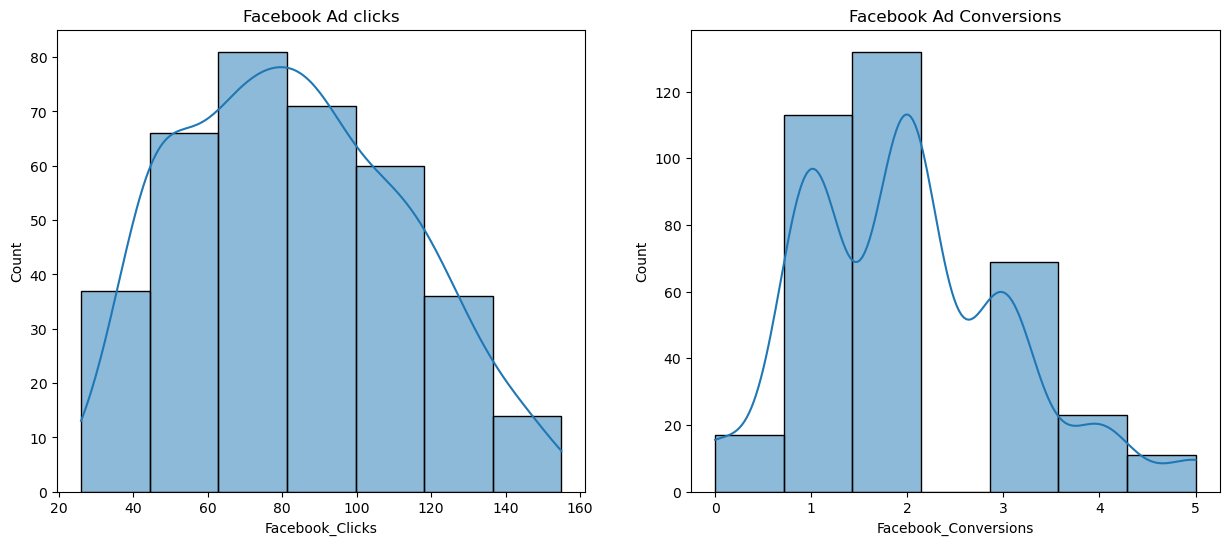

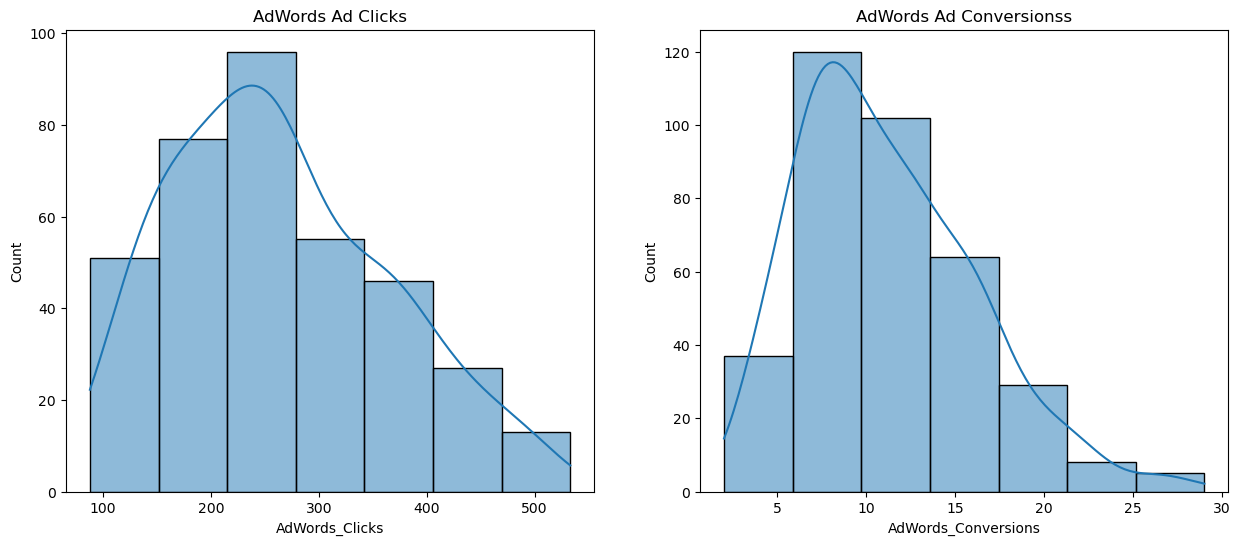

In [7]:
plt.figure(figsize = (15,6))
plt.subplot(1,2,1)
plt.title("Facebook Ad clicks")
sns.histplot(df["Facebook_Clicks"], bins = 7, edgecolor= 'k', kde= True)
plt.subplot(1,2,2)
plt.title("Facebook Ad Conversions")
sns.histplot(df["Facebook_Conversions"], bins = 7, edgecolor= 'k', kde= True)
plt.show()

plt.figure(figsize = (15,6))
plt.subplot(1,2,1)
plt.title("AdWords Ad Clicks")
sns.histplot(df["AdWords_Clicks"], bins = 7, edgecolor= 'k', kde= True)
plt.subplot(1,2,2)
plt.title("AdWords Ad Conversionss")
sns.histplot(df["AdWords_Conversions"], bins = 7, edgecolor= 'k', kde= True)
plt.show()

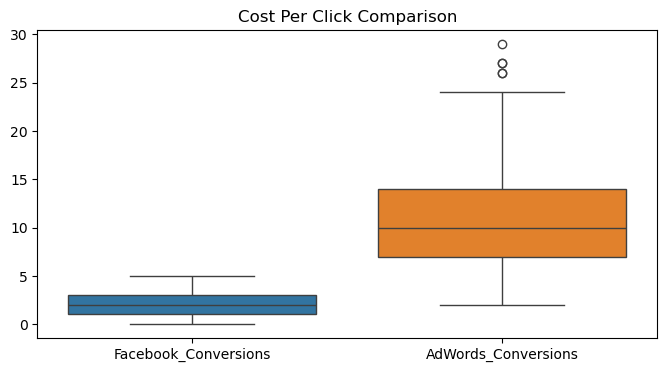

In [8]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df[["Facebook_Conversions", "AdWords_Conversions"]])
plt.title("Cost Per Click Comparison")
plt.show()

In [9]:
df[df["AdWords_Conversions"]> 24.5] #Checing if outliers are genuine or some data error

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost,Facebook_CTR,Facebook_Conversion_Rate,Facebook_CPC,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost,AdWords_CTR,AdWords_Conversion_Rate,AdWords_CPC
16,2019-01-17,2630,44,1,1603.316344,0.016730,0.022727,36.439008,11996,515,29,19930.14870,0.042931,0.056311,38.699318
107,2019-04-18,4562,66,2,2484.931363,0.014467,0.030303,37.650475,11521,462,27,28616.81504,0.040101,0.058442,61.941158
121,2019-05-02,8932,106,4,2869.276077,0.011867,0.037736,27.068642,10713,448,26,24728.87792,0.041818,0.058036,55.198388
271,2019-09-29,2646,44,1,1159.754179,0.016629,0.022727,26.358050,11723,507,27,18447.47498,0.043248,0.053254,36.385552
305,2019-11-02,6590,85,3,1845.573989,0.012898,0.035294,21.712635,11164,499,26,23759.91032,0.044697,0.052104,47.615051


How frequently do we observe days with high number of conversion compared to days with the low number of conversion

In [10]:
def create_conversion_category(conversion_col):
    category= []
    for conversion in df[conversion_col]:
        if conversion < 4:
            category.append("less then 4")
        elif 4<= conversion <13:
            category.append("4-12")
        elif 13<= conversion <21:
            category.append("13-20")
        else:
            category.append("More then 20")
    return category

df["Facebook conversion category"] = create_conversion_category("Facebook_Conversions")
df["Adwords conversion category"] = create_conversion_category( "AdWords_Conversions")

In [11]:
df[["Facebook_Conversions", "Facebook conversion category", "AdWords_Conversions", "Adwords conversion category"]].head()

,Facebook_Conversions,Facebook conversion category,AdWords_Conversions,Adwords conversion category
0,1,less then 4,14,13-20
1,2,less then 4,7,4-12
2,2,less then 4,14,13-20
3,3,less then 4,18,13-20
4,2,less then 4,11,4-12


In [12]:
df["Facebook conversion category"].value_counts()

Facebook conversion category
less then 4    331
4-12            34
Name: count, dtype: int64

In [14]:
df["Adwords conversion category"].value_counts()

Adwords conversion category
4-12            231
13-20           112
More then 20     18
less then 4       4
Name: count, dtype: int64

In [17]:
Facebook = pd.DataFrame(df["Facebook conversion category"]).value_counts().reset_index().rename(columns= {"Facebook conversion category": "Category"})

In [18]:
Adwords = pd.DataFrame(df["Adwords conversion category"]).value_counts().reset_index().rename(columns= {"Adwords conversion category": "Category"})

In [20]:
Category_df = pd.merge(Facebook, Adwords, on = 'Category', how = 'outer').fillna(0)
Category_df

,Category,count_x,count_y
0,13-20,0.0,112
1,4-12,34.0,231
2,More then 20,0.0,18
3,less then 4,331.0,4


In [22]:
Category_df = Category_df.iloc[[3,1,0,2]]
Category_df

,Category,count_x,count_y
3,less then 4,331.0,4
1,4-12,34.0,231
0,13-20,0.0,112
2,More then 20,0.0,18


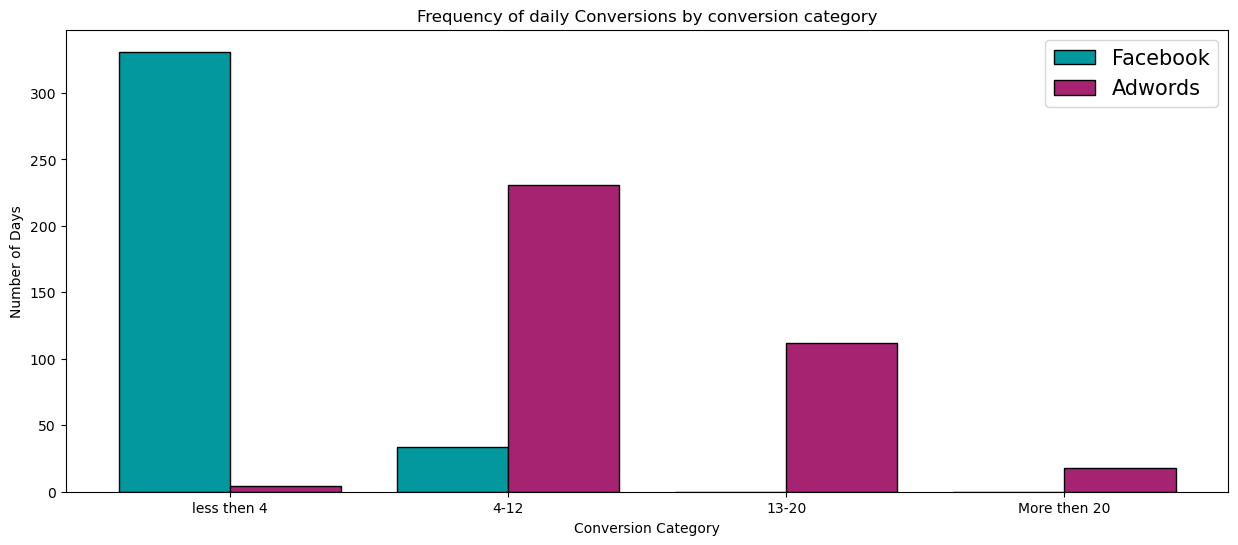

In [26]:
x_axis = np.arange(len(Category_df))
plt.figure(figsize= (15,6))
plt.bar(x_axis-0.2, Category_df['count_x'], 0.4, label= 'Facebook', color= '#03989E', linewidth= 1, edgecolor= 'k')
plt.bar(x_axis+0.2, Category_df['count_y'], 0.4, label= 'Adwords', color= '#A62372', linewidth= 1, edgecolor= 'k')

plt.xticks(x_axis, Category_df['Category'])
plt.xlabel('Conversion Category')
plt.ylabel('Number of Days')
plt.title('Frequency of daily Conversions by conversion category')
plt.legend(fontsize= 15)
plt.show()

- The data suggests Adwordshad more frequenct higher conversion days than Facebook, which either had low conversion rate (less than 4) or moderate ones (4-12).
- There is a significant variance in the number of high-conversion days between two different campaigns.
- The absence of any days with conversions between 13-20 and more then 20 in Facebook indicates a need to review what strategies were changed or what factors could have influenced these numbers.

### Do click on the ad really leads to more sales?


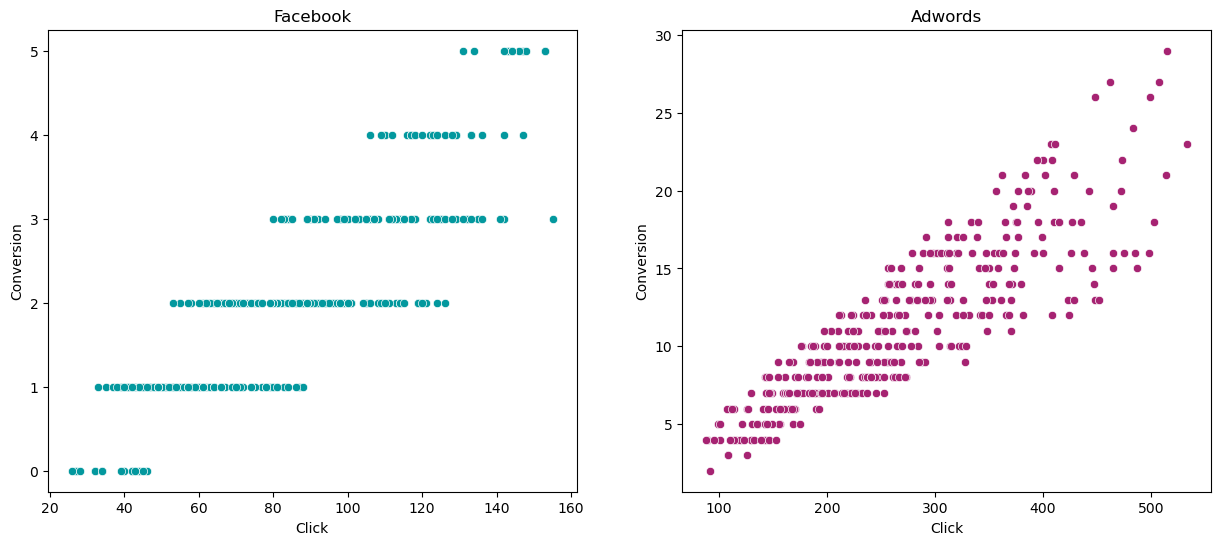

In [28]:
plt.figure(figsize= (15,6))
plt.subplot(1,2,1)
plt.title('Facebook')
sns.scatterplot(x= df['Facebook_Clicks'], y= df['Facebook_Conversions'], color= '#03989E')
plt.xlabel('Click')
plt.ylabel('Conversion')
plt.subplot(1,2,2)
plt.title('Adwords')
sns.scatterplot(x= df['AdWords_Clicks'], y= df['AdWords_Conversions'], color= '#A62372')
plt.xlabel('Click')
plt.ylabel('Conversion')
plt.show()

In [31]:
facebook_corr= df[['Facebook_Conversions', 'Facebook_Clicks']].corr()
facebook_corr

,Facebook_Conversions,Facebook_Clicks
Facebook_Conversions,1.000000,0.858999
Facebook_Clicks,0.858999,1.000000


In [32]:
Adwords_corr= df[['AdWords_Conversions', 'AdWords_Clicks']].corr()
Adwords_corr

,AdWords_Conversions,AdWords_Clicks
AdWords_Conversions,1.000000,0.872506
AdWords_Clicks,0.872506,1.000000


In [35]:
print('Correlation Coeff \n_________________')
print('Facebook:', round(facebook_corr.values[0,1],2))
print('Adwords:', round(Adwords_corr.values[0,1],2))

Correlation Coeff 
_________________
Facebook: 0.86
Adwords: 0.87


##### Both Facebook And Adwords are showing positive correlation which means there is positive liner relation between clicks and sales. This indicates as the number of clicks on facebook and Adwords increase, Sales trends to increase as well.

## Hypothesis Testing
Hypothesis: Advertising on Adwords will result in a greater number of conversions compared to advertising on AdWords.

Null Hypothesis (HO): There is no difference in the number of conversions between Facebook and AdWords, or the number of conversions from Facebook is greater than or equal to those from Adwords.

HO: µAdWords < μ_Facebook

Alternate Hypothesis (H1): The number of conversions from Adwords is greater than the number of conversions from Facebook.

H1: µAdWords > μ_Facebook

In [45]:
print('Mean Conversion\n_________________')
print('Facebook:', round(df['Facebook_Conversions'].mean(),2))
print('Adwords:', round(df['AdWords_Conversions'].mean(),2))
t_stat, p_value = ttest_ind(a= df['Facebook_Conversions'], b= df['AdWords_Conversions'], equal_var= False)
print('\nT statistic', t_stat, '\np-value', p_value)

if p_value < 0.05:
    print("\np-value is less then significance value, reject the null hypothesis")
else: 
    print("\np-value is greater then significance value, accept the null hypothesis")

Mean Conversion
_________________
Facebook: 2.0
Adwords: 11.18

T statistic -34.41191801980557 
p-value 1.4810752353035617e-121

p-value is less then significance value, reject the null hypothesis


## Regression Analysis
What will happen if i do go with the Adwords ad? How many Adwords conversion can i expect given a certain number of Adwords ad clicks?

In [63]:
X = df[['AdWords_Clicks']]
y = df['AdWords_Conversions']
reg_model = LinearRegression()
reg_model.fit(X, y)
prediction = reg_model.predict(X)

r2= r2_score(y, prediction)*100
mse= mean_squared_error(y, prediction)
print('Accuracy (R2 Score):', round(r2, 2), '%')
print('Mean Squared Error:', round(mse, 2))

Accuracy (R2 Score): 76.13 %
Mean Squared Error: 5.89


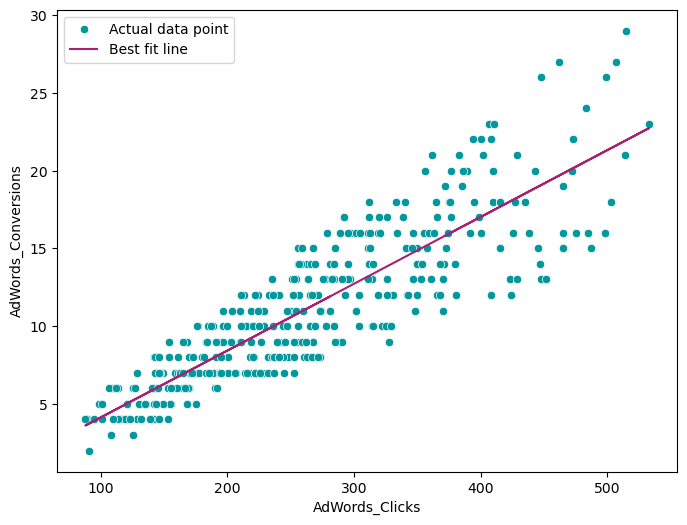

In [64]:
plt.figure(figsize= (8,6))
sns.scatterplot(x= df['AdWords_Clicks'], y= df['AdWords_Conversions'], color = '#03989e', label= 'Actual data point')
plt.plot(df['AdWords_Clicks'], prediction, color = '#A62372', label= 'Best fit line')
plt.legend()
plt.show()
         

In [65]:
print(f'for {50} clicks, Expected Conversion: {round(reg_model.predict([[50]])[0], 2)}')
print(f'for {80} clicks, Expected Conversion: {round(reg_model.predict([[80]])[0], 2)}')

for 50 clicks, Expected Conversion: 1.98
for 80 clicks, Expected Conversion: 3.27


## Analyzing Facebook Campaign metrics over time 

In [66]:
df.head()

,Date,Facebook_Views,Facebook_Clicks,Facebook_Conversions,Facebook_Cost,Facebook_CTR,Facebook_Conversion_Rate,Facebook_CPC,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost,AdWords_CTR,AdWords_Conversion_Rate,AdWords_CPC,Facebook conversion category,Adwords conversion category
0,2019-01-01,3360,49,1,1890.694138,0.014583,0.020408,38.585595,7436,281,14,15262.013890,0.037789,0.049822,54.313217,less then 4,13-20
1,2019-01-02,7890,113,2,3988.731928,0.014322,0.017699,35.298513,4562,159,7,7480.942113,0.034853,0.044025,47.049950,less then 4,4-12
2,2019-01-03,7726,90,2,2038.344103,0.011649,0.022222,22.648268,6485,263,14,18544.718620,0.040555,0.053232,70.512238,less then 4,13-20
3,2019-01-04,7691,135,3,3211.546629,0.017553,0.022222,23.789234,9895,435,18,26448.313440,0.043962,0.041379,60.800721,less then 4,13-20
4,2019-01-05,6272,101,2,2256.736225,0.016103,0.019802,22.343923,7354,210,11,13575.896910,0.028556,0.052381,64.647128,less then 4,4-12


In [67]:
df= df[['Date', 'AdWords_Views', 'AdWords_Clicks', 'AdWords_Conversions', 'AdWords_Cost', 'AdWords_CTR', 'AdWords_Conversion_Rate', 'AdWords_CPC']]

In [71]:
df.head()

,Date,AdWords_Views,AdWords_Clicks,AdWords_Conversions,AdWords_Cost,AdWords_CTR,AdWords_Conversion_Rate,AdWords_CPC
0,2019-01-01,7436,281,14,15262.013890,0.037789,0.049822,54.313217
1,2019-01-02,4562,159,7,7480.942113,0.034853,0.044025,47.049950
2,2019-01-03,6485,263,14,18544.718620,0.040555,0.053232,70.512238
3,2019-01-04,9895,435,18,26448.313440,0.043962,0.041379,60.800721
4,2019-01-05,7354,210,11,13575.896910,0.028556,0.052381,64.647128


#### At what times of the month or days of the week do we observe the conversions?

In [73]:
df['month']= df['Date'].dt.month
df['week']= df['Date'].dt.weekday

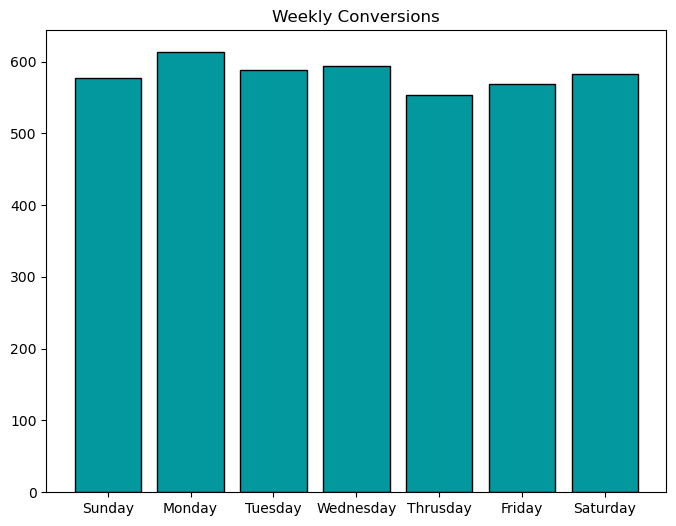

In [74]:
plt.figure(figsize= (8,6))
plt.title('Weekly Conversions')
weekly_conversion= df.groupby('week')[['AdWords_Conversions']].sum()
week_names= ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thrusday', 'Friday', 'Saturday']
plt.bar(week_names, weekly_conversion['AdWords_Conversions'], color = "#03989E", edgecolor= 'k')
plt.show()

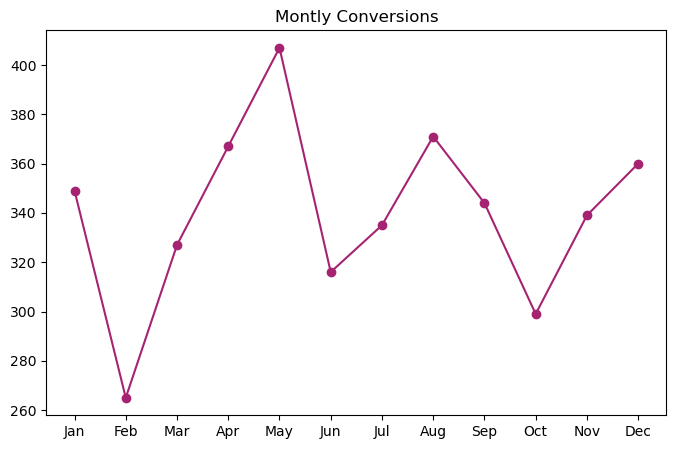

In [76]:
plt.figure(figsize = (8,5))
plt.title('Montly Conversions')
monthly_conversions = df.groupby('month')[['AdWords_Conversions']].sum()
month_names= ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.plot(month_names, monthly_conversions['AdWords_Conversions'], '-o', color= '#A62372')
plt.show()

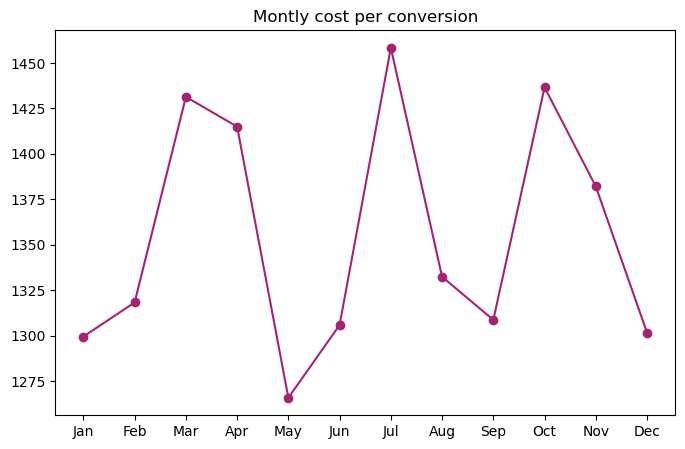

In [77]:
plt.figure(figsize = (8,5))
plt.title('Montly cost per conversion')
monthly_df = df.groupby('month')[['AdWords_Conversions', 'AdWords_Cost']].sum()
monthly_df['cost per conversion']= monthly_df['AdWords_Cost']/ monthly_df['AdWords_Conversions']
plt.plot(month_names, monthly_df['cost per conversion'], '-o', color= '#A62372')
plt.show()

In [80]:
score, p_value, _ = coint(df['AdWords_Cost'], df['AdWords_Conversions'])
print(f'cointegration test score: {score}')
print(f'P value: {p_value}')

if p_value< 0.05:
    print("p_value is less then significance value, Reject the null hypothesis")
else:
    print("p_value is Greater then significance value, Accept the null hypothesis")

cointegration test score: -11.144718286927695
P value: 3.736994867651016e-19
p_value is less then significance value, Reject the null hypothesis


- Since the p-value is significance lower then the chosen significance level, we reject the null hypothesis. This incicates that there is a long-term equilibrium relationship betweeen advertising spend(cost0 and conversions.
- Businesses can use this undersatanding of the stable reletionship between cost and conversions to optimize their advertising strategies. Bu investing in campaigns that demonstrate a strong return on investment and adjesting based on performance, companies can maximixe conversions while minimizng cost.